In [12]:
from getpass import getuser # Libaray to copy things
from pathlib import Path # Object oriented libary to deal with paths
from dask.utils import format_bytes
from distributed import Client, progress, wait # Libaray to orchestrate distributed resources
#from dask_jobqueue import SLURMCluster # Setting up distributed memories via slurm
import numpy as np # Pythons standard array library
import xarray as xr # Libary to work with labeled n-dimensional data
import dask # Distributed data libary
import dask.distributed
import multiprocessing
from dask.diagnostics import ProgressBar
import glob, os
from matplotlib.patches import Patch
from scipy.ndimage import gaussian_filter1d
from subprocess import run, PIPE
import sys
import gc
from concurrent.futures import ProcessPoolExecutor
import seaborn as sns
import warnings
warnings.filterwarnings(action='ignore')
dask.config.config.get('distributed').get('dashboard').update({'link':'{JUPYTERHUB_SERVICE_PREFIX}/proxy/{port}/status'})
import pandas as pd
from scipy.interpolate import CloughTocher2DInterpolator, LinearNDInterpolator, NearestNDInterpolator

In [13]:
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from matplotlib import pyplot as plt # Standard Plotting library
from matplotlib import cm
from matplotlib.colors import ListedColormap, LinearSegmentedColormap
from matplotlib.ticker import (MultipleLocator, FormatStrFormatter, AutoMinorLocator)
from cartopy import crs as ccrs # Cartography library
from cartopy.mpl.ticker import LongitudeFormatter, LatitudeFormatter
import cartopy.feature as cfeature
import matplotlib.ticker as mticker
import matplotlib.tri as tri

In [14]:
#'''Provides information about the CPU and starts the dask client'''
ncpu = multiprocessing.cpu_count()
processes = False
nworker = 1
threads = ncpu // nworker
print(f"Number of CPUs: {ncpu}, number of threads: {threads}, number of workers: {nworker}, processes: {processes}")
client = Client(processes=processes,
 threads_per_worker=threads,
 n_workers=nworker,
 memory_limit='1000GB'
 )

Number of CPUs: 64, number of threads: 64, number of workers: 1, processes: False


In [15]:
mask = '01'      # '01': hourly precipitation > 0.1 mm, '05': > 0.5 mm

# CESM2-LE hourly ensemble (10 members), ssp370 output of cesm2_hourly_precip_cover_calc.py --experiment ssp370
CESM2_DIR       = '/home/jwille/xenon_data/NextGEMS/mid_lat_precip/cesm2_ens_hourly'
CESM2_THRESHOLD = {'01': 0.1, '05': 0.5}   # mm per hour, for each mask
PERIOD_1        = (2021, 2034)             # inclusive
PERIOD_2        = (2035, 2049)


In [16]:
import re

# hourly % of land area with precipitation > threshold (cos(lat)-weighted, already in %), one file per member
thr = CESM2_THRESHOLD[mask]
pat = re.compile(r'^cesm2_hourly_precip_cover_(?P<member>[^_]+)_ssp370_30-60N\.nc$')
members = {}             # member -> DataArray (time) of hourly values
for f in sorted(os.listdir(CESM2_DIR)):
    if not (m := pat.match(f)):
        continue
    da = xr.open_dataset(os.path.join(CESM2_DIR, f), use_cftime=True)['wet_land_pct']
    da = da.sel(threshold=thr, method='nearest')
    if abs(float(da.threshold) - thr) > 1e-9:
        raise ValueError(f'{f}: no threshold {thr} mm/h')
    members[m['member']] = da.load()
    yr = da.time.dt.year.values
    print(f'CESM2 {m["member"]}: {da.sizes["time"]} hours, {yr.min()}-{yr.max()}')
print(f'\n{len(members)} members, > {thr} mm/h')


CESM2 1011.001: 128064 hours, 2021-2049
CESM2 1031.002: 128064 hours, 2021-2049
CESM2 1051.003: 128064 hours, 2021-2049
CESM2 1071.004: 128064 hours, 2021-2049
CESM2 1091.005: 128064 hours, 2021-2049
CESM2 1111.006: 128064 hours, 2021-2049
CESM2 1131.007: 128064 hours, 2021-2049
CESM2 1151.008: 128064 hours, 2021-2049
CESM2 1171.009: 128064 hours, 2021-2049
CESM2 1191.010: 128064 hours, 2021-2049

10 members, > 0.1 mm/h


In [17]:
print(sorted(members))

['1011.001', '1031.002', '1051.003', '1071.004', '1091.005', '1111.006', '1131.007', '1151.008', '1171.009', '1191.010']


In [18]:
def pooled(period):
    """All hours of all members in the period (inclusive), as one 1-D array."""
    out = []
    for name, da in members.items():
        yr = da.time.dt.year.values
        sel = (yr >= period[0]) & (yr <= period[1])
        n_years = len(np.unique(yr[sel]))
        if n_years != period[1] - period[0] + 1:
            print(f'WARNING {name}: {n_years} of {period[1] - period[0] + 1} years in {period}')
        out.append(da.values[sel])
    return np.concatenate(out)


cesm2_hist = pooled(PERIOD_1)     # names kept from the single-member version
cesm2_fut = pooled(PERIOD_2)


In [19]:
print(f'{PERIOD_1[0]}-{PERIOD_1[1]}: {cesm2_hist.size} hours (all members pooled)')

2021-2034: 618240 hours (all members pooled)


In [20]:
print(f'{PERIOD_2[0]}-{PERIOD_2[1]}: {cesm2_fut.size} hours (all members pooled)')

2035-2049: 662400 hours (all members pooled)


## CESM2 ensemble (all members pooled)

In [21]:
# the hourly files are already % of the land area at 30-60N (cos(lat)-weighted, land = MASK > 0)
percent_cesm2_hist = cesm2_hist[np.isfinite(cesm2_hist)]
percent_cesm2_fut = cesm2_fut[np.isfinite(cesm2_fut)]
for name, v in [(f'{PERIOD_1[0]}-{PERIOD_1[1]}', percent_cesm2_hist), (f'{PERIOD_2[0]}-{PERIOD_2[1]}', percent_cesm2_fut)]:
    q25, q50, q75 = np.percentile(v, [25, 50, 75])
    print(f'{name}: median {q50:.2f}%, IQR {q25:.2f}-{q75:.2f}%, mean {v.mean():.2f}%')


2021-2034: median 14.46%, IQR 12.40-16.62%, mean 14.57%
2035-2049: median 14.31%, IQR 12.24-16.57%, mean 14.46%


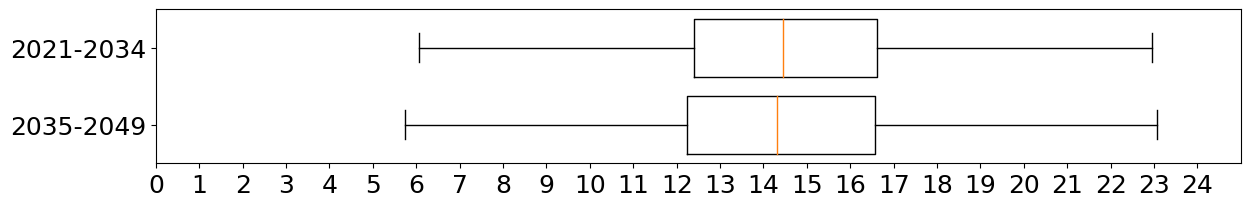

In [22]:
data1 = percent_cesm2_hist     # 2021-2034, all members pooled
data2 = percent_cesm2_fut      # 2035-2049, all members pooled
fig, ax = plt.subplots(figsize=(14, 2))
ax.boxplot([data1, data2], vert=False, positions=[1.2, 1],sym='')

if mask == '01':
    xmin, xmax = 0, 25
elif mask == '02':
    xmin, xmax = 0, 30
elif mask == '05':
    xmin, xmax = 0,8 
ax.set_xlim(xmin, xmax)
xticks = np.arange(xmin, xmax, 1)
ax.set_xticks(xticks)
ax.tick_params(labelsize=18)

# y-ticks
ax.set_yticks([1.2, 1])
ax.set_yticklabels([f'{PERIOD_1[0]}-{PERIOD_1[1]}', f'{PERIOD_2[0]}-{PERIOD_2[1]}'])

# Remove tick marks (both axes, major & minor)
ax.grid(False)

# Tighten y-limits (a little margin around the boxes)
ax.set_ylim(0.9, 1.3)
plt.savefig('/home/jwille/images/global_paper/mid_lat_land_cesm2_B&W_fut_precip_coverage_'+mask+'_ens.pdf', format='pdf',bbox_inches='tight')

plt.show()
